# VOiCES Event Detection — Distractor-Condition Classification

## Dataset source and task alignment
This notebook accesses the **Lab41/VOiCES-subset GitHub repository directly**. You do not need to upload a ZIP file or manually download the dataset.

The repository contains eight audio archives (`VOiCES_90_1.tar` ... `VOiCES_90_8.tar`). The notebook downloads these archives to the temporary Colab runtime, indexes their WAV filenames, selects a stratified 10% sample, and extracts only the selected WAV recordings for model training.

**Target classes:** `none`, `babb` (babble), `tele` (television), and `musi` (music).

**Important:** The target is recording-level distractor/background-condition classification. It is not time-localized event detection. The repository README describes this as a 90-degree-position subset and its CSV workshop materials as speaker-gender classification; this notebook uses the audio filenames' distractor labels instead.


## 1. Setup and mount Google Drive

In [1]:
!pip -q install numpy pandas scikit-learn matplotlib seaborn librosa soundfile tqdm requests

from pathlib import Path
import tarfile, os, re, json, random, warnings, requests, shutil
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Training device:', DEVICE)

# Download only the eight archives in the Lab41 90-degree subset repository.
# The repository's TAR files are about tens of MB each; this is much smaller
# than downloading the full official VOiCES corpus.
REPO_RAW = 'https://raw.githubusercontent.com/Lab41/VOiCES-subset/master'
ARCHIVE_DIR = Path('/content/voices_subset_archives')
ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
tar_entries = []
for i in range(1, 9):
    name = f'VOiCES_90_{i}.tar'
    url = f'{REPO_RAW}/{name}'
    local_path = ARCHIVE_DIR / name
    if not local_path.exists() or local_path.stat().st_size == 0:
        print(f'Downloading {name} ...')
        with requests.get(url, stream=True, timeout=(30, 300)) as response:
            response.raise_for_status()
            with open(local_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
    print(name, '->', round(local_path.stat().st_size / 1e6, 2), 'MB')
    tar_entries.append(local_path)

print('Downloaded TAR archives:', len(tar_entries))
print('PyTorch:', torch.__version__)


Mounted at /content/drive
Training device: cuda
VOiCES_90_1.tar -> 47.62 MB
VOiCES_90_2.tar -> 48.12 MB
VOiCES_90_3.tar -> 48.16 MB
VOiCES_90_4.tar -> 47.25 MB
VOiCES_90_5.tar -> 47.09 MB
VOiCES_90_6.tar -> 46.11 MB
VOiCES_90_7.tar -> 46.9 MB
VOiCES_90_8.tar -> 48.4 MB
Downloaded TAR archives: 8
PyTorch: 2.14.1+cu130


## 2. Inspect the downloaded TAR archives

In [2]:
print('TAR archives found:', len(tar_entries))
for archive_path in tar_entries:
    print('-', archive_path.name, f'({archive_path.stat().st_size/1e6:.1f} MB)')
if len(tar_entries) != 8:
    raise RuntimeError('Expected eight VOiCES_90_*.tar archives from the Lab41 repository.')


TAR archives found: 8
- VOiCES_90_1.tar (47.6 MB)
- VOiCES_90_2.tar (48.1 MB)
- VOiCES_90_3.tar (48.2 MB)
- VOiCES_90_4.tar (47.2 MB)
- VOiCES_90_5.tar (47.1 MB)
- VOiCES_90_6.tar (46.1 MB)
- VOiCES_90_7.tar (46.9 MB)
- VOiCES_90_8.tar (48.4 MB)


## 3. Build an audio manifest without extracting all recordings

The distractor class is encoded in the audio filename, for example:
`Lab41-SRI-VOiCES-rm1-musi-sp5126-ch036956-sg0011-mc07-stu-beh-dg090.wav`.

The class token is one of `none`, `babb`, `tele`, or `musi`. This cell reads TAR headers and records filenames; it does not extract audio.

In [3]:
LABELS = ['none', 'babb', 'tele', 'musi']

# Actual archive filenames use:
# Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg0013-mc03-stu-mid-dg090.wav
# Important: the field is "sg" (not "seg").
name_pattern = re.compile(
    r'Lab41-SRI-VOiCES-rm\d+-(none|babb|tele|musi)-sp\d+-ch\d+-sg\d+-mc\d+-stu-[a-z]+-dg\d+\.wav$',
    re.IGNORECASE
)

manifest = []
for archive_path in tar_entries:
    print('Indexing TAR:', archive_path.name)
    with tarfile.open(archive_path, mode='r:*') as tf:
        for member in tf:
            if not member.isfile() or not member.name.lower().endswith('.wav'):
                continue
            base = Path(member.name).name
            match = name_pattern.search(base)
            if match:
                manifest.append({
                    'archive': str(archive_path),
                    'member': member.name,
                    'basename': base,
                    'label': match.group(1).lower(),
                    'size_bytes': member.size
                })

manifest_df = pd.DataFrame(manifest)
if manifest_df.empty:
    raise RuntimeError(
        'No WAV members matched the actual VOiCES filename pattern. '
        'Print a few member basenames and adjust the parser.'
    )

print('Indexed recordings:', len(manifest_df))
display(manifest_df['label'].value_counts().reindex(LABELS, fill_value=0).to_frame('recordings'))
display(manifest_df.head())


Indexing TAR: VOiCES_90_1.tar
Indexing TAR: VOiCES_90_2.tar
Indexing TAR: VOiCES_90_3.tar
Indexing TAR: VOiCES_90_4.tar
Indexing TAR: VOiCES_90_5.tar
Indexing TAR: VOiCES_90_6.tar
Indexing TAR: VOiCES_90_7.tar
Indexing TAR: VOiCES_90_8.tar
Indexed recordings: 909


,recordings
label,
none,227
babb,228
tele,223
musi,231


,archive,member,basename,label,size_bytes
0,/content/voices_subset_archives/VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-babb-sp1472-ch285314-sg00...,babb,512204
1,/content/voices_subset_archives/VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-tele-sp2294-ch161714-sg00...,tele,542764
2,/content/voices_subset_archives/VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-none-sp3972-ch005791-sg00...,none,527564
3,/content/voices_subset_archives/VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm2-tele-sp5386-ch004145-sg00...,tele,529004
4,/content/voices_subset_archives/VOiCES_90_1.tar,Users/mbarrios/Documents/VOICES/IQT_Github_rep...,Lab41-SRI-VOiCES-rm1-musi-sp2532-ch157475-sg00...,musi,501484


In [5]:
from pathlib import Path

AUDIO_DIR = Path('/content/voices_selected_audio')
OUT_DIR = Path('/content/drive/MyDrive/VOiCES_Event_Classification')

for folder in [
    AUDIO_DIR,
    OUT_DIR / 'tables',
    OUT_DIR / 'metrics',
    OUT_DIR / 'figures',
    OUT_DIR / 'models'
]:
    folder.mkdir(parents=True, exist_ok=True)

## 4. Select a stratified 10% subset and extract only those WAV files

In [6]:
SAMPLE_FRACTION = 0.10

counts = manifest_df['label'].value_counts()
eligible = counts[counts >= 10].index.tolist()
manifest_df = manifest_df[manifest_df['label'].isin(eligible)].copy()
if manifest_df['label'].nunique() < 2:
    raise RuntimeError('Not enough recordings across at least two distractor classes.')

sample_n = max(int(round(len(manifest_df) * SAMPLE_FRACTION)), manifest_df['label'].nunique() * 10)
sample_n = min(sample_n, len(manifest_df))
selected, _ = train_test_split(
    manifest_df, train_size=sample_n, random_state=SEED, stratify=manifest_df['label']
)
selected = selected.reset_index(drop=True)
print(f'Selected {len(selected):,} recordings ({len(selected)/len(manifest_df):.1%})')
display(selected['label'].value_counts().reindex(LABELS, fill_value=0).to_frame('selected'))

# Extract only selected WAV members from their respective TAR archives.
selected_keys = set(zip(selected['archive'], selected['member']))
extracted = {}
for archive_path in tar_entries:
    archive_key = str(archive_path)
    keys_for_tar = {m for a, m in selected_keys if a == archive_key}
    if not keys_for_tar:
        continue
    print(f'Extracting {len(keys_for_tar)} selected recordings from {archive_path.name}')
    with tarfile.open(archive_path, mode='r:*') as tf:
        for member_name in keys_for_tar:
            try:
                member = tf.getmember(member_name)
            except KeyError:
                continue
            src = tf.extractfile(member)
            if src is None:
                continue
            target = AUDIO_DIR / (str(len(extracted)).zfill(6) + '_' + Path(member.name).name)
            with open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)
            extracted[(archive_key, member.name)] = str(target)

selected['audio_path'] = [
    extracted.get((r['archive'], r['member'])) for _, r in selected.iterrows()
]
selected = selected.dropna(subset=['audio_path']).reset_index(drop=True)
print('Successfully extracted:', len(selected))
if len(selected) < 30:
    raise RuntimeError('Too few selected WAV files were extracted to create reliable train/validation/test splits.')

selected.to_csv(OUT_DIR/'tables'/'selected_recordings_manifest.csv', index=False)
print('Extracted audio storage (MB):', round(sum(Path(p).stat().st_size for p in selected['audio_path'])/1e6, 2))


Selected 91 recordings (10.0%)


,selected
label,
none,23
babb,23
tele,22
musi,23


Extracting 10 selected recordings from VOiCES_90_1.tar
Extracting 13 selected recordings from VOiCES_90_2.tar
Extracting 13 selected recordings from VOiCES_90_3.tar
Extracting 11 selected recordings from VOiCES_90_4.tar
Extracting 4 selected recordings from VOiCES_90_5.tar
Extracting 10 selected recordings from VOiCES_90_6.tar
Extracting 13 selected recordings from VOiCES_90_7.tar
Extracting 17 selected recordings from VOiCES_90_8.tar
Successfully extracted: 91
Extracted audio storage (MB): 44.73


## 5. Convert selected recordings to log-Mel spectrograms

In [8]:
from pathlib import Path

TARGET_SR = 16000
CLIP_SECONDS = 5
N_FFT = 512
HOP_LENGTH = 160
N_MELS = 64

OUT_DIR = Path('/content/drive/MyDrive/VOiCES_Event_Classification')
AUDIO_DIR = Path('/content/voices_selected_audio')

for folder in [
    AUDIO_DIR,
    OUT_DIR / 'tables',
    OUT_DIR / 'metrics',
    OUT_DIR / 'figures',
    OUT_DIR / 'models'
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Configuration ready!")

Configuration ready!


In [9]:
def make_logmel(audio_path):
    signal, sr = sf.read(audio_path, dtype='float32')
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if sr != TARGET_SR:
        signal = librosa.resample(signal, orig_sr=sr, target_sr=TARGET_SR)
    target_samples = int(TARGET_SR * CLIP_SECONDS)
    if len(signal) < target_samples:
        signal = np.pad(signal, (0, target_samples - len(signal)))
    else:
        signal = signal[:target_samples]
    mel = librosa.feature.melspectrogram(
        y=signal, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=50, fmax=TARGET_SR//2, power=2.0
    )
    return librosa.power_to_db(mel, ref=np.max).astype(np.float32)

X_items, y_items, kept_paths = [], [], []
for _, row in tqdm(selected.iterrows(), total=len(selected)):
    try:
        X_items.append(make_logmel(row['audio_path']))
        y_items.append(row['label'])
        kept_paths.append(row['audio_path'])
    except Exception as exc:
        print('Skipping unreadable audio:', row['audio_path'], '|', exc)

if len(X_items) < 30:
    raise RuntimeError('Fewer than 30 valid audio features were extracted.')

X = np.stack(X_items)[:, None, :, :]
class_names = sorted(set(y_items))
class_to_id = {name:i for i,name in enumerate(class_names)}
y = np.asarray([class_to_id[name] for name in y_items], dtype=np.int64)
print('X shape:', X.shape, 'classes:', class_names)
np.savez_compressed(OUT_DIR/'tables'/'logmel_dataset.npz', X=X, y=y, class_names=class_names)

  0%|          | 0/91 [00:00<?, ?it/s]

X shape: (91, 1, 64, 501) classes: ['babb', 'musi', 'none', 'tele']


## 6. Create train/validation/test splits

In [10]:
# 70% train, 15% validation, 15% test; stratified by distractor condition.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print('Train:', len(y_train), 'Validation:', len(y_val), 'Test:', len(y_test))
print('Train distribution:', dict(zip(*np.unique(y_train, return_counts=True))))
print('Validation distribution:', dict(zip(*np.unique(y_val, return_counts=True))))
print('Test distribution:', dict(zip(*np.unique(y_test, return_counts=True))))

Train: 63 Validation: 14 Test: 14
Train distribution: {np.int64(0): np.int64(16), np.int64(1): np.int64(16), np.int64(2): np.int64(16), np.int64(3): np.int64(15)}
Validation distribution: {np.int64(0): np.int64(3), np.int64(1): np.int64(4), np.int64(2): np.int64(3), np.int64(3): np.int64(4)}
Test distribution: {np.int64(0): np.int64(4), np.int64(1): np.int64(3), np.int64(2): np.int64(4), np.int64(3): np.int64(3)}


## 7. Train a CNN using the Colab GPU

In [12]:
# Model training configuration
BATCH_SIZE = 16
EPOCHS = 20
PATIENCE = 5

print("BATCH_SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("PATIENCE:", PATIENCE)

BATCH_SIZE: 16
EPOCHS: 20
PATIENCE: 5


In [13]:
class MelDataset(Dataset):
    def __init__(self, features, targets):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.long)
    def __len__(self): return len(self.targets)
    def __getitem__(self, index): return self.features[index], self.targets[index]

train_loader = DataLoader(MelDataset(X_train,y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(MelDataset(X_val,y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(MelDataset(X_test,y_test), batch_size=BATCH_SIZE, shuffle=False)

class VOiCESEventCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,16,3,padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(64,n_classes))
    def forward(self,x): return self.classifier(self.features(x))

model = VOiCESEventCNN(len(class_names)).to(DEVICE)
weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
best_val_loss = float('inf'); best_state = None; patience_count = 0
history = {'train_loss':[],'val_loss':[],'val_accuracy':[]}

for epoch in range(EPOCHS):
    model.train(); train_losses=[]
    for xb,yb in train_loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        optimizer.zero_grad()
        loss=criterion(model(xb),yb)
        loss.backward(); optimizer.step()
        train_losses.append(loss.item())

    model.eval(); val_losses=[]; val_true=[]; val_pred=[]
    with torch.no_grad():
        for xb,yb in val_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            logits=model(xb)
            val_losses.append(criterion(logits,yb).item())
            val_true.extend(yb.cpu().numpy())
            val_pred.extend(logits.argmax(1).cpu().numpy())

    tr_loss=float(np.mean(train_losses)); vl_loss=float(np.mean(val_losses))
    val_acc=accuracy_score(val_true,val_pred)
    history['train_loss'].append(tr_loss); history['val_loss'].append(vl_loss)
    history['val_accuracy'].append(float(val_acc))
    print(f'Epoch {epoch+1:02d}: train_loss={tr_loss:.4f}, val_loss={vl_loss:.4f}, val_acc={val_acc:.4f}')

    if vl_loss < best_val_loss:
        best_val_loss=vl_loss
        best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        patience_count=0
    else:
        patience_count += 1
        if patience_count >= PATIENCE:
            print('Early stopping triggered.')
            break

if best_state is not None:
    model.load_state_dict(best_state)
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'sample_rate': TARGET_SR,
    'n_mels': N_MELS,
    'clip_seconds': CLIP_SECONDS
}, OUT_DIR/'models'/'voices_distractor_cnn.pt')

Epoch 01: train_loss=1.4013, val_loss=1.8357, val_acc=0.2143
Epoch 02: train_loss=1.3512, val_loss=1.6180, val_acc=0.2143
Epoch 03: train_loss=1.2894, val_loss=1.5686, val_acc=0.2143
Epoch 04: train_loss=1.2941, val_loss=1.4810, val_acc=0.2143
Epoch 05: train_loss=1.2716, val_loss=1.4351, val_acc=0.2143
Epoch 06: train_loss=1.2995, val_loss=1.4342, val_acc=0.2143
Epoch 07: train_loss=1.2379, val_loss=1.4345, val_acc=0.2143
Epoch 08: train_loss=1.2236, val_loss=1.4602, val_acc=0.2143
Epoch 09: train_loss=1.2302, val_loss=1.4638, val_acc=0.2143
Epoch 10: train_loss=1.2396, val_loss=1.4931, val_acc=0.1429
Epoch 11: train_loss=1.2102, val_loss=1.5390, val_acc=0.1429
Early stopping triggered.


## 8. Evaluate on the held-out test set

              precision    recall  f1-score   support

        babb       0.40      0.50      0.44         4
        musi       0.00      0.00      0.00         3
        none       0.44      1.00      0.62         4
        tele       0.00      0.00      0.00         3

    accuracy                           0.43        14
   macro avg       0.21      0.38      0.26        14
weighted avg       0.24      0.43      0.30        14



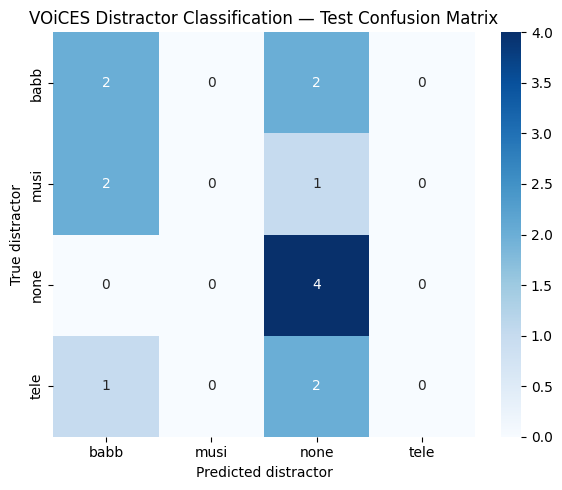

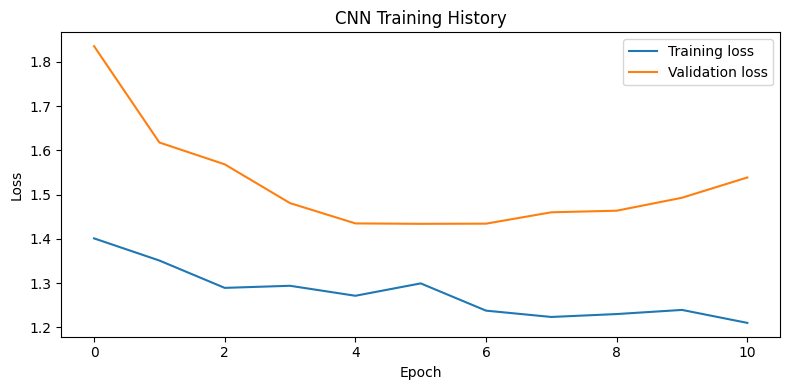

All results saved to: /content/drive/MyDrive/VOiCES_Event_Classification


In [14]:
model.eval(); y_true=[]; y_pred=[]
with torch.no_grad():
    for xb,yb in test_loader:
        logits=model(xb.to(DEVICE))
        y_true.extend(yb.numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())

report = classification_report(
    y_true, y_pred, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)
print(classification_report(
    y_true, y_pred, labels=np.arange(len(class_names)),
    target_names=class_names, zero_division=0
))

metrics = {
    'task': 'VOiCES recording-level distractor-condition classification',
    'classes': class_names,
    'sample_fraction': SAMPLE_FRACTION,
    'manifest_recordings': int(len(manifest_df)),
    'selected_recordings': int(len(selected)),
    'valid_feature_recordings': int(len(X)),
    'train_size': int(len(y_train)),
    'validation_size': int(len(y_val)),
    'test_size': int(len(y_test)),
    'accuracy': float(accuracy_score(y_true,y_pred)),
    'macro_f1': float(f1_score(y_true,y_pred,average='macro')),
    'weighted_f1': float(f1_score(y_true,y_pred,average='weighted')),
    'classification_report': report
}
with open(OUT_DIR/'metrics'/'test_metrics.json','w') as f:
    json.dump(metrics,f,indent=2)

pd.DataFrame(history).to_csv(OUT_DIR/'metrics'/'training_history.csv',index=False)

cm=confusion_matrix(y_true,y_pred,labels=np.arange(len(class_names)))
fig,ax=plt.subplots(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names,ax=ax)
ax.set_xlabel('Predicted distractor'); ax.set_ylabel('True distractor')
ax.set_title('VOiCES Distractor Classification — Test Confusion Matrix')
plt.tight_layout()
plt.savefig(OUT_DIR/'figures'/'confusion_matrix.png',dpi=180)
plt.show()

plt.figure(figsize=(8,4))
plt.plot(history['train_loss'],label='Training loss')
plt.plot(history['val_loss'],label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('CNN Training History')
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/'figures'/'training_history.png',dpi=180)
plt.show()

print('All results saved to:', OUT_DIR)